# 02. Reviewing the collected data

This notebook visualizes the data collected with `01_collect_data.ipynb` (`video.mp4` + `actions.csv` for each episode).
Before you go on to training (`03_train_bc.ipynb`), check here that you collected the data you wanted.
This notebook only reads data. It does not change data collection or training.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("../data")
MANIFEST_PATH = DATA_DIR / "manifest.csv"
EPISODES_DIR = DATA_DIR / "episodes"

manifest = pd.read_csv(MANIFEST_PATH)
manifest

,episode_id,num_frames,score,x_pos_max,coins,flag_get,time_remaining,truncated,timestamp
0,ep_20261020_131320,681,800,2009,2,False,332,False,2026-10-20 13:13:20
1,ep_20261020_131352,928,200,2741,0,False,308,False,2026-10-20 13:13:52
2,ep_20261020_131430,1127,900,3161,2,True,288,False,2026-10-20 13:14:31
3,ep_20261020_131512,418,300,2044,1,False,359,False,2026-10-20 13:15:12
4,ep_20261020_131518,155,0,680,0,False,385,False,2026-10-20 13:15:18
5,ep_20261020_131526,207,0,710,0,False,380,False,2026-10-20 13:15:26
6,ep_20261020_131557,902,400,1722,0,False,310,False,2026-10-20 13:15:57
7,ep_20261020_131611,399,400,1814,1,False,361,False,2026-10-20 13:16:11
8,ep_20261020_131630,542,300,2473,0,False,346,False,2026-10-20 13:16:30
9,ep_20261020_131653,627,200,2768,0,False,338,False,2026-10-20 13:16:53


## Summary statistics

In [2]:
print(f"episodes: {len(manifest)}")
print(f"clear rate (flag_get): {manifest['flag_get'].mean():.1%}")
manifest[["num_frames", "score", "x_pos_max", "coins", "time_remaining"]].describe()

episodes: 14
clear rate (flag_get): 7.1%


,num_frames,score,x_pos_max,coins,time_remaining
count,14.000000,14.000000,14.000000,14.000000,14.000000
mean,558.214286,335.714286,1991.285714,0.642857,344.714286
std,302.575402,276.258360,844.843038,0.744946,30.266581
min,152.000000,0.000000,680.000000,0.000000,288.000000
25%,330.750000,200.000000,1577.250000,0.000000,330.500000
50%,584.500000,300.000000,2026.500000,0.500000,342.000000
75%,702.000000,400.000000,2750.000000,1.000000,367.750000
max,1127.000000,900.000000,3161.000000,2.000000,385.000000


## How good was the play? (Skill score)

This rates one episode with a score from 0 to 100.

```
progress = min(x_pos_max / 3161, 1)                          # progress rate (3161 = x position of the goal)
clear    = 1 if flag_get else 0                              # did Mario clear the stage?
t_used   = 400 - time_remaining                              # in-game time used
speed    = clear × clip((T_SLOW - t_used) / (T_SLOW - T_FAST), 0, 1)
points   = clear × min(score / SCORE_TARGET, 1)               # in-game score (coins, enemies, etc.)

Skill = 100 × (0.40·progress + 0.10·clear + 0.20·speed + 0.30·points)
```

- **Just clearing the stage gives 50 points** (progress 40% + clear 10%). Clearing 1-1 is not very
  hard, so the other 50 points come from speed (20%) and in-game score (30%).
  Reaching the goal gets its own bonus (10%) because "died just before the goal" and "cleared"
  are different in quality.
- **Speed and score only count for cleared episodes.** If Mario died, a short time only means he died early,
  not that the play was good, so we multiply by `clear` to turn it off. The score works the same way:
  an episode that does not clear is rated only on progress, so its maximum is 40 points.
  Time comes from the in-game timer, not from `num_frames`. (During area changes, such as going into a pipe,
  the environment moves frames forward internally, so the number of recorded frames does not match the real time.)
- **The in-game score (`score`) rates collecting coins and defeating enemies together.** A coin gives 200 points,
  a stomp gives 100 or more (it doubles for stomps in a row), a broken block gives 50, and a mushroom, flower, or star gives 1000.
  The episode ends the moment Mario touches the flagpole, so the score does not include
  the flagpole points or the time bonus. Speed is already measured by `speed`, so time is not counted twice.
- Rows with `truncated=True` (stopped with Esc) are left out. The player just stopped, so they say nothing about skill.

The constants and the formula are defined in `competition_config.py` (shared with 01 and 04, do not edit it).
`SCORE_TARGET` (5000 points) is about 10 coins, about 10 enemies, and 2 power-ups.

In [3]:
# The formula and its constants live in competition_config.py (shared with 01/04)
from competition_config import add_skill_score

# Rows cut short with ESC only mean the player stopped, so leave them out
scored = add_skill_score(manifest[~manifest["truncated"]])

print(f"scored: {len(scored)} episodes (excluded: {int(manifest['truncated'].sum())})")
print(f"mean skill: {scored['skill'].mean():.1f}   best: {scored['skill'].max():.1f}")
print(f"clear rate: {scored['clear'].mean():.0%}")

scored.sort_values("skill", ascending=False)[
    ["episode_id", "x_pos_max", "flag_get", "t_used", "coins", "score",
     "progress", "speed", "points", "skill"]
].round(2)

scored: 14 episodes (excluded: 0)
mean skill: 32.2   best: 91.8
clear rate: 7%


,episode_id,x_pos_max,flag_get,t_used,coins,progress,speed,collect,skill
2,ep_20261020_131430,3161,True,112,2,1.00,0.99,0.2,91.80
10,ep_20261020_131718,2767,False,70,1,0.88,0.00,0.1,40.39
11,ep_20261020_131740,2753,False,66,1,0.87,0.00,0.1,40.19
9,ep_20261020_131653,2768,False,62,0,0.88,0.00,0.0,39.41
1,ep_20261020_131352,2741,False,92,0,0.87,0.00,0.0,39.02
8,ep_20261020_131630,2473,False,54,0,0.78,0.00,0.0,35.21
0,ep_20261020_131320,2009,False,68,2,0.64,0.00,0.2,30.60
3,ep_20261020_131512,2044,False,41,1,0.65,0.00,0.1,30.10
7,ep_20261020_131611,1814,False,39,1,0.57,0.00,0.1,26.82
6,ep_20261020_131557,1722,False,90,0,0.54,0.00,0.0,24.51


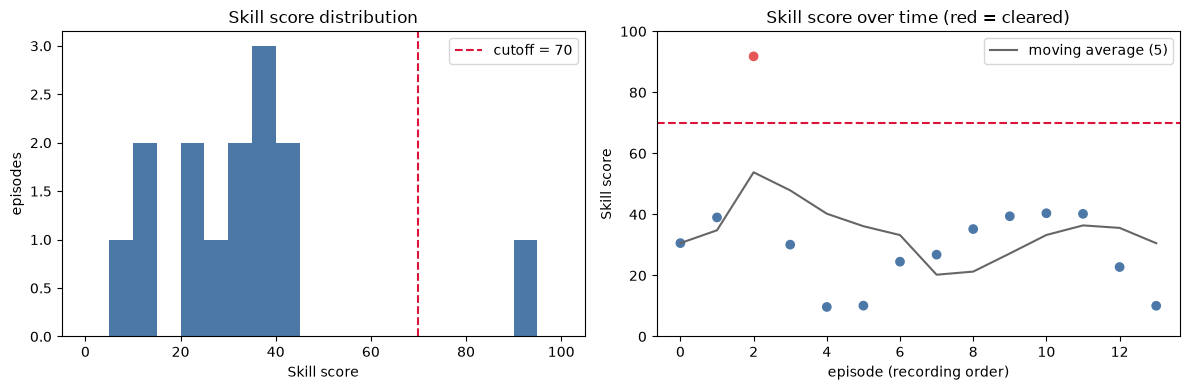

skill >= 70: 1 / 14 episodes
['ep_20261020_131430']


In [4]:
# Skill score distribution, and whether play improves as episodes accumulate
GOOD_SKILL = 50  # cutoff for keeping an episode as training data (only cleared ones reach 50)

fig, (ax_hist, ax_time) = plt.subplots(1, 2, figsize=(12, 4))

ax_hist.hist(scored["skill"], bins=20, range=(0, 100), color="#4c78a8")
ax_hist.axvline(GOOD_SKILL, color="crimson", linestyle="--", label=f"cutoff = {GOOD_SKILL}")
ax_hist.set_xlabel("Skill score")
ax_hist.set_ylabel("episodes")
ax_hist.set_title("Skill score distribution")
ax_hist.legend()

chronological = scored.sort_values("timestamp").reset_index(drop=True)
colors = ["#e45756" if c else "#4c78a8" for c in chronological["clear"]]
ax_time.scatter(chronological.index, chronological["skill"], c=colors)
ax_time.plot(
    chronological.index,
    chronological["skill"].rolling(5, min_periods=1).mean(),
    color="#666",
    label="moving average (5)",
)
ax_time.axhline(GOOD_SKILL, color="crimson", linestyle="--")
ax_time.set_xlabel("episode (recording order)")
ax_time.set_ylabel("Skill score")
ax_time.set_ylim(0, 100)
ax_time.set_title("Skill score over time (red = cleared)")
ax_time.legend()

plt.tight_layout()
plt.show()

good = scored[scored["skill"] >= GOOD_SKILL].sort_values("skill", ascending=False)
print(f"skill >= {GOOD_SKILL}: {len(good)} / {len(scored)} episodes")
print(good["episode_id"].tolist())

## Action distribution (all episodes)

To find class imbalance before training, this counts how many frames were recorded for each of the 7 actions.

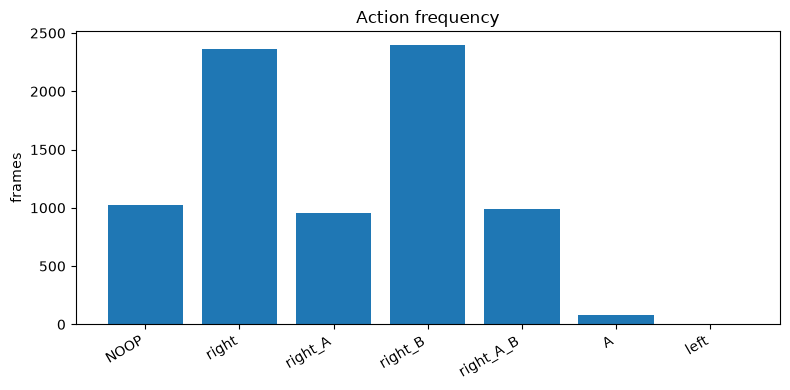

In [5]:
from collections import Counter

from gym_super_mario_bros.actions import SIMPLE_MOVEMENT

ACTION_NAMES = ["_".join(a) if a else "NOOP" for a in SIMPLE_MOVEMENT]

action_counts = Counter()
for ep_dir in sorted(EPISODES_DIR.glob("ep_*")):
    actions_csv = ep_dir / "actions.csv"
    if not actions_csv.exists():
        continue
    action_counts.update(pd.read_csv(actions_csv)["action"].tolist())

counts = [action_counts.get(i, 0) for i in range(len(SIMPLE_MOVEMENT))]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ACTION_NAMES, counts)
ax.set_ylabel("frames")
ax.set_title("Action frequency")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Sample frames from an episode

Change `episode_id` to look at a different episode.

ep_20261020_131320: video=681 frames, actions.csv=681 frames


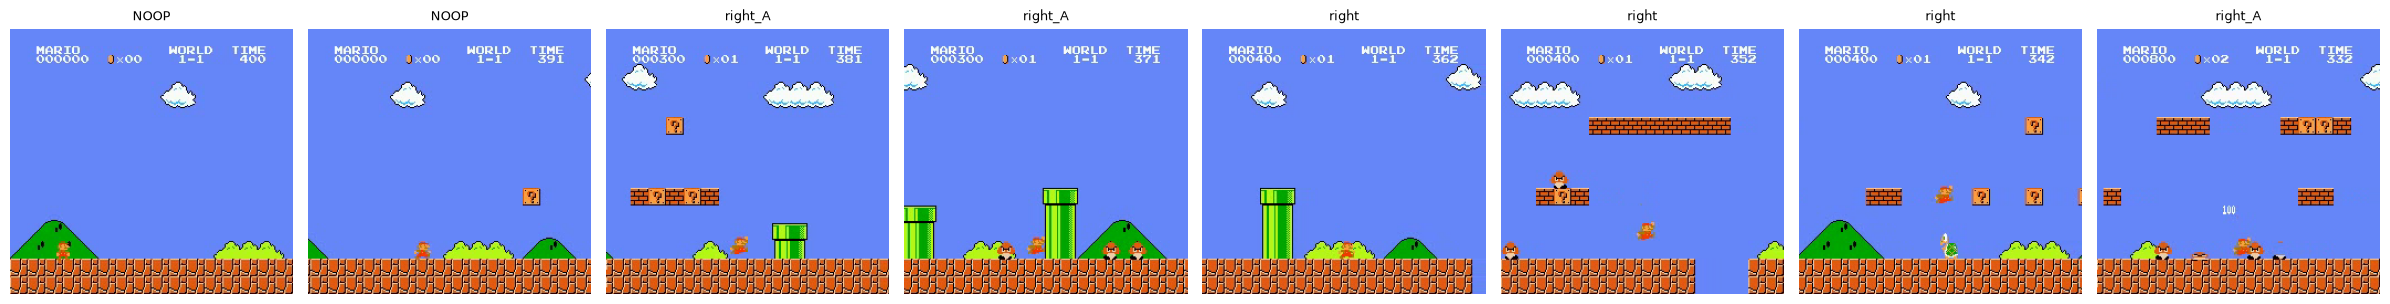

In [6]:
import cv2
import numpy as np

episode_id = manifest["episode_id"].iloc[0]  # change this to the episode you want to inspect
ep_dir = EPISODES_DIR / episode_id
actions_df = pd.read_csv(ep_dir / "actions.csv")

cap = cv2.VideoCapture(str(ep_dir / "video.mp4"))
num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"{episode_id}: video={num_frames} frames, actions.csv={len(actions_df)} frames")

n_samples = min(8, num_frames)
sample_idx = np.linspace(0, num_frames - 1, num=n_samples, dtype=int)

sample_frames = []
for idx in sample_idx:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ok, frame_bgr = cap.read()
    sample_frames.append(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB) if ok else None)
cap.release()

fig, axes = plt.subplots(1, n_samples, figsize=(3 * n_samples, 3))
if n_samples == 1:
    axes = [axes]
for ax, idx, frame in zip(axes, sample_idx, sample_frames):
    action_idx = int(actions_df.loc[actions_df["frame_idx"] == idx, "action"].iloc[0])
    if frame is not None:
        ax.imshow(frame)
    ax.set_title(ACTION_NAMES[action_idx], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Action sequence plot

This shows which action was taken at which time in the chosen episode (for example, when Mario jumped).

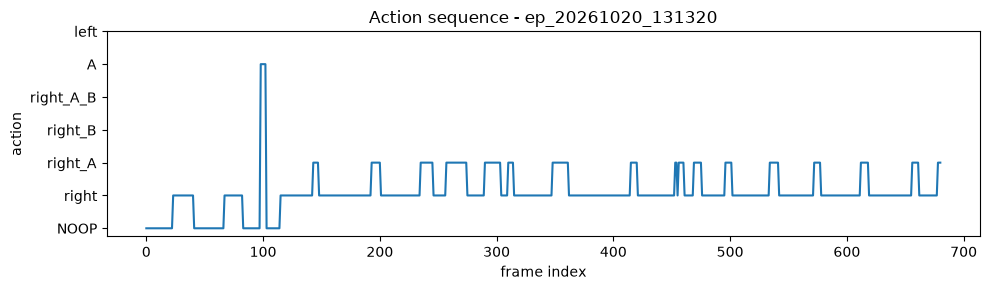

In [7]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(actions_df["frame_idx"], actions_df["action"])
ax.set_xlabel("frame index")
ax.set_ylabel("action")
ax.set_yticks(range(len(SIMPLE_MOVEMENT)))
ax.set_yticklabels(ACTION_NAMES)
ax.set_title(f"Action sequence - {episode_id}")
plt.tight_layout()
plt.show()

## Cleaning the data

If you find an episode that is clearly wrong, for example it has only a few frames or a recording mistake,
delete its `data/episodes/ep_YYYYMMDD_HHMMSS/` folder (`video.mp4` and `actions.csv`)
and delete the matching row in `data/manifest.csv` by hand.
Episodes with a very low Skill score above (Mario did not move forward, or died right away) are good candidates.

Episode IDs are made from the recording time, so each one is unique. When episodes used sequential numbers,
IDs such as `ep_0000` were reused, and the manifest rows no longer matched the folders.
(This data has been migrated. The old manifest is saved as `data/manifest_backup_*.csv`.)